# Sistema de agrupación de casas: California Housing

**Objetivo:** agrupar las casas de California según **dónde están** (latitud y longitud) y el **ingreso medio**
de la zona, y entrenar después un modelo supervisado capaz de asignar ese grupo a casas nuevas.

Es un flujo habitual con datos sin etiquetar:

1. Un modelo **no supervisado** (K-Means) crea las etiquetas.
2. Un modelo **supervisado** aprende a reproducirlas y se usa en producción.

**Recorrido:** carga y división train/test → K-Means con 6 clusters → predicción sobre test →
clasificador supervisado → guardado de modelos → conclusiones.

## 0. Configuración

In [1]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.cluster import KMeans
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay, accuracy_score, classification_report, silhouette_score,
)
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

SEED = 42
N_CLUSTERS = 6
FEATURES = ["Latitude", "Longitude", "MedInc"]

PROJECT_ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
RAW_PATH = PROJECT_ROOT / "data" / "raw" / "housing.csv"
DATA_URL = "https://breathecode.herokuapp.com/asset/internal-link?id=809&path=housing.csv"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
MODELS_DIR = PROJECT_ROOT / "models"

pd.set_option("display.width", 200)
print("Raíz del proyecto:", PROJECT_ROOT)

Raíz del proyecto: /workspaces/aie-pt3-machine-learning-2-nestornegrin


## 1. Carga del conjunto de datos

Leemos la copia local de `data/raw/housing.csv` y, si no existe, la descargamos del enlace del enunciado.

In [2]:
if not RAW_PATH.exists():
    RAW_PATH.parent.mkdir(parents=True, exist_ok=True)
    pd.read_csv(DATA_URL).to_csv(RAW_PATH, index=False)

housing = pd.read_csv(RAW_PATH)
print("Dataset completo:", housing.shape)
print("Columnas:", housing.columns.tolist())

df = housing[FEATURES].copy()
print("\nNulos:", df.isna().sum().to_dict())
print("Filas duplicadas:", df.duplicated().sum())
df.describe().round(2)

Dataset completo: (20640, 9)
Columnas: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude', 'MedHouseVal']

Nulos: {'Latitude': 0, 'Longitude': 0, 'MedInc': 0}
Filas duplicadas: 5


,Latitude,Longitude,MedInc
count,20640.00,20640.00,20640.00
mean,35.63,-119.57,3.87
std,2.14,2.00,1.90
min,32.54,-124.35,0.50
25%,33.93,-121.80,2.56
50%,34.26,-118.49,3.53
75%,37.71,-118.01,4.74
max,41.95,-114.31,15.00


Solo usamos las tres columnas que pide el enunciado:

- **`Latitude` / `Longitude`:** ubicación del grupo de bloques censales.
- **`MedInc`:** ingreso medio de los hogares, en **decenas de miles de dólares** (3,5 equivale a 35.000 $ al año).

No hay nulos. Si aparece alguna fila duplicada, corresponde a grupos de bloques distintos con los mismos valores, así que se mantiene.

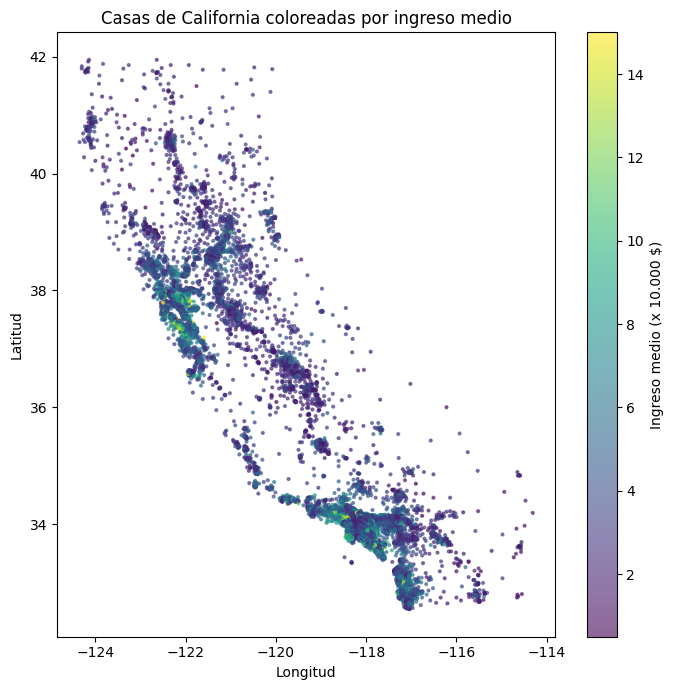

In [3]:
fig, ax = plt.subplots(figsize=(7, 7))
points = ax.scatter(df["Longitude"], df["Latitude"], c=df["MedInc"], cmap="viridis", s=4, alpha=0.6)
fig.colorbar(points, ax=ax, label="Ingreso medio (x 10.000 $)")
ax.set_title("Casas de California coloreadas por ingreso medio")
ax.set_xlabel("Longitud")
ax.set_ylabel("Latitud")
plt.tight_layout()
plt.show()

El mapa de California aparece solo con los puntos. Se distinguen las dos grandes áreas metropolitanas
(**San Francisco** al norte y **Los Ángeles–San Diego** al sur), con los ingresos más altos concentrados en la costa.

### 1.1 División train / test

Dividimos **antes** de agrupar: K-Means aprende solo con train, y test sirve para comprobar que asigna bien
casas que no ha visto.

In [4]:
X_train, X_test = train_test_split(df, test_size=0.2, random_state=SEED)
print(f"Train: {len(X_train)} casas · Test: {len(X_test)} casas")

Train: 16512 casas · Test: 4128 casas


## 2. K-Means con 6 clusters

### 2.1 ¿Por qué escalar antes?

K-Means agrupa por **distancia**. Si las variables están en escalas distintas, la que tenga más rango domina.

In [5]:
display(X_train.agg(["min", "max", "std"]).round(2))

,Latitude,Longitude,MedInc
min,32.55,-124.35,0.5
max,41.95,-114.31,15.0
std,2.14,2.01,1.9


Las tres variables tienen rangos parecidos (unos 10 grados de latitud y de longitud, y unos 15 de ingreso),
pero no iguales. Para que **ubicación e ingreso pesen lo mismo**, como pide el objetivo, estandarizamos cada
variable (media 0 y desviación 1) con `StandardScaler`.

El escalador y K-Means van en un **pipeline**: así el modelo guardado escala solo las casas nuevas
y nunca se nos olvida ese paso.

In [6]:
kmeans = make_pipeline(
    StandardScaler(),
    KMeans(n_clusters=N_CLUSTERS, n_init=10, random_state=SEED),
)
kmeans.fit(X_train)

train = X_train.copy()
train["cluster"] = kmeans.predict(X_train)
print("Valores de cluster:", sorted(int(c) for c in train["cluster"].unique()), "· tipo:", train["cluster"].dtype)

Valores de cluster: [0, 1, 2, 3, 4, 5] · tipo: int32


### 2.2 La columna `cluster`

K-Means devuelve **números enteros del 0 al 5**. Ese número es solo un nombre: el cluster 4 no es "mayor"
que el 2. Por eso lo convertimos en una variable **categórica**, para que ni los gráficos ni los modelos
lo traten como una cantidad.

In [7]:
train["cluster"] = pd.Categorical(train["cluster"], categories=range(N_CLUSTERS))
print("Tipo tras convertir:", train["cluster"].dtype)
train["cluster"].value_counts().sort_index().to_frame("casas")

Tipo tras convertir: category


,casas
cluster,
0,1321
1,3380
2,453
3,3931
4,2239
5,5188


### 2.3 Perfil de cada cluster

Centro de cada grupo en las unidades originales, más su tamaño.

In [8]:
profile = (
    train.groupby("cluster", observed=True)[FEATURES]
    .mean()
    .assign(casas=train["cluster"].value_counts().sort_index())
    .sort_values("MedInc", ascending=False)
    .round(2)
)
profile

,Latitude,Longitude,MedInc,casas
cluster,,,,
2,34.90,-119.24,10.44,453
4,37.70,-121.94,5.52,2239
1,33.87,-118.02,5.31,3380
3,38.35,-121.90,2.84,3931
5,33.82,-117.82,2.78,5188
0,36.08,-119.73,2.63,1321


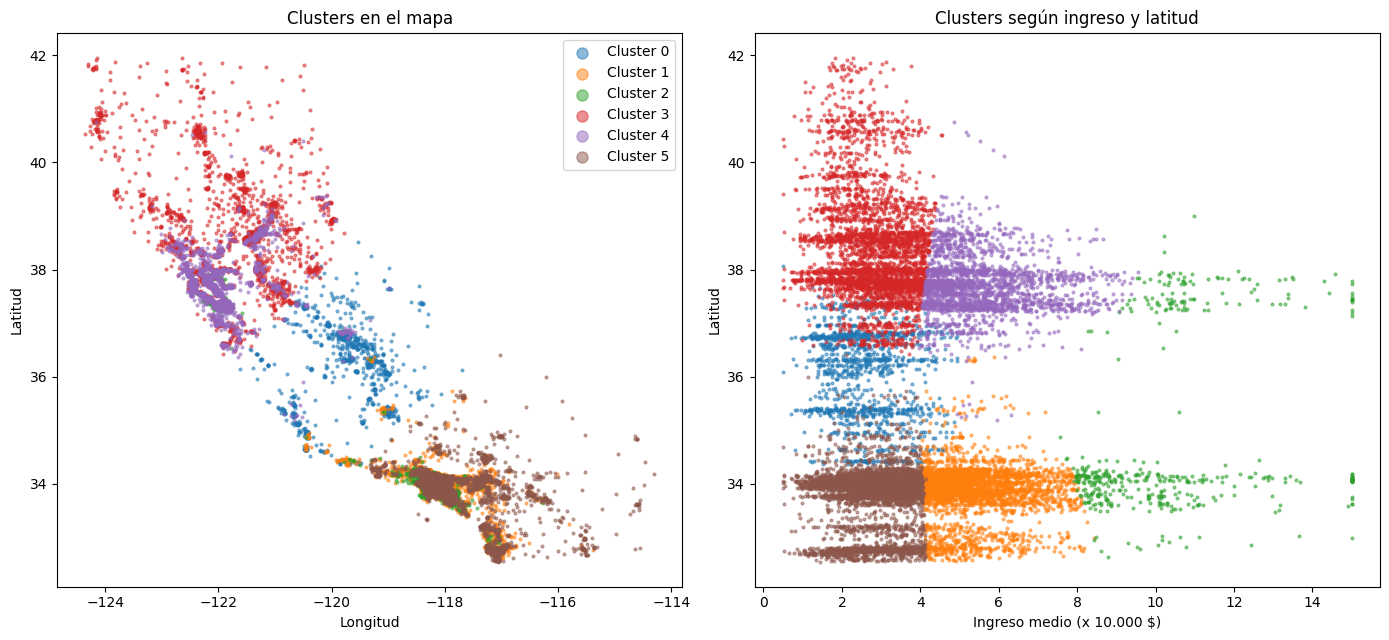

In [9]:
CLUSTER_COLORS = plt.cm.tab10.colors[:N_CLUSTERS]


def plot_clusters(ax_map, ax_inc, data, marker="o", size=4, alpha=0.5, edge=None, label_suffix=""):
    """Dibuja los puntos en el mapa (lon/lat) y en el plano ingreso/latitud, coloreados por cluster."""
    for c in range(N_CLUSTERS):
        part = data[data["cluster"] == c]
        kwargs = dict(color=CLUSTER_COLORS[c], marker=marker, s=size, alpha=alpha, edgecolors=edge)
        ax_map.scatter(part["Longitude"], part["Latitude"], label=f"Cluster {c}{label_suffix}", **kwargs)
        ax_inc.scatter(part["MedInc"], part["Latitude"], **kwargs)


fig, (ax_map, ax_inc) = plt.subplots(1, 2, figsize=(14, 6.5))
plot_clusters(ax_map, ax_inc, train)
ax_map.set(title="Clusters en el mapa", xlabel="Longitud", ylabel="Latitud")
ax_inc.set(title="Clusters según ingreso y latitud", xlabel="Ingreso medio (x 10.000 $)", ylabel="Latitud")
ax_map.legend(markerscale=4, loc="upper right")
plt.tight_layout()
plt.show()

### 2.4 ¿Son buenos 6 clusters?

El enunciado fija 6 clusters. Como comprobación, calculamos el **coeficiente de silueta** para varios valores de k
(de −1 a 1: cuanto más alto, más compactos y separados están los grupos).

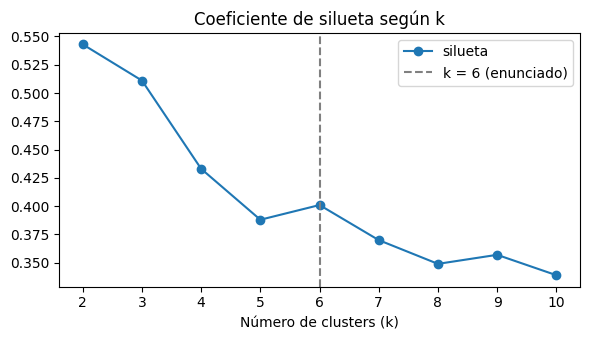

,2,3,4,5,6,7,8,9,10
silueta,0.543,0.511,0.433,0.388,0.401,0.37,0.349,0.357,0.339


In [10]:
scaled_train = kmeans[0].transform(X_train)
silhouette = {}
for k in range(2, 11):
    labels = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit_predict(scaled_train)
    silhouette[k] = silhouette_score(scaled_train, labels, sample_size=5000, random_state=SEED)

sil = pd.Series(silhouette, name="silueta").round(3)
ax = sil.plot(marker="o", figsize=(6, 3.5), title="Coeficiente de silueta según k")
ax.axvline(N_CLUSTERS, color="grey", linestyle="--", label="k = 6 (enunciado)")
ax.set_xlabel("Número de clusters (k)")
ax.legend()
plt.tight_layout()
plt.show()
sil.to_frame().T

### 2.5 Descripción de los clusters

Mirando los dos gráficos, K-Means ha combinado **tres zonas** y **tres niveles de ingreso**:

| Cluster | Zona | Ingreso medio | Casas (train) | Lectura |
|---|---|---|---|---|
| **2** | San Francisco **y** Los Ángeles | **104.400 $** | 453 (2,7 %) | Barrios de ingreso **muy alto** (más de ~80.000 $), en ambas metrópolis |
| **4** | Norte: Bahía de San Francisco | 55.200 $ | 2.239 (13,6 %) | Norte con ingreso **medio-alto** |
| **1** | Sur: Los Ángeles – San Diego | 53.100 $ | 3.380 (20,5 %) | Sur con ingreso **medio-alto** |
| **3** | Norte: Sacramento y condados del norte | 28.400 $ | 3.931 (23,8 %) | Norte con ingreso **bajo-medio** |
| **5** | Sur: Los Ángeles – San Diego e interior sur | 27.800 $ | 5.188 (31,4 %) | Sur con ingreso **bajo-medio**: el grupo más grande |
| **0** | Valle Central (Fresno, Bakersfield) | 26.300 $ | 1.321 (8,0 %) | Interior agrícola con el ingreso **más bajo** |

**Lo que se ve en el gráfico de puntos:**

- **La latitud separa el norte del sur** con un corte claro hacia los 36–37°. El Valle Central queda como una franja intermedia propia.
- **El ingreso separa cada zona en dos** con un umbral muy nítido en torno a **41.000 $** (`MedInc` ≈ 4,1). Se ve como un corte vertical en el gráfico de la derecha.
- **El cluster 2 ignora la geografía:** por encima de ~80.000 $ el ingreso pesa más que la ubicación y agrupa a los barrios ricos de San Francisco y de Los Ángeles juntos. El escalado consigue justo eso: que ubicación e ingreso cuenten por igual.

**Sobre k = 6:** la silueta más alta es la de k = 2 (0,543), que solo separaría norte y sur. Con k = 6 la silueta (0,401)
es algo mejor que con k = 5 (0,388) y da grupos con un significado de negocio claro (zona + nivel de ingreso), así que es una elección razonable.

## 3. Predicción con el conjunto de test

Asignamos cluster a las casas de test con el K-Means **ya entrenado** y las superponemos al gráfico anterior,
con un marcador distinto (cruces con borde negro).

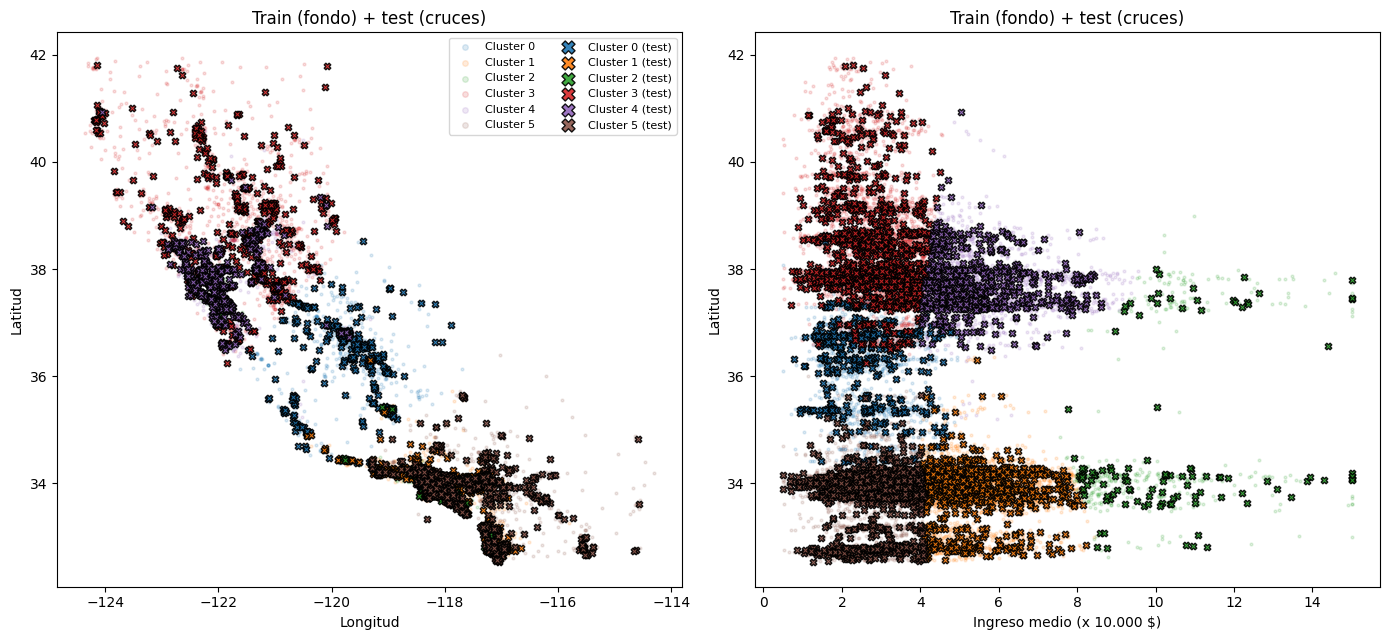

In [11]:
test = X_test.copy()
test["cluster"] = pd.Categorical(kmeans.predict(X_test), categories=range(N_CLUSTERS))

fig, (ax_map, ax_inc) = plt.subplots(1, 2, figsize=(14, 6.5))
plot_clusters(ax_map, ax_inc, train, alpha=0.15)
plot_clusters(ax_map, ax_inc, test, marker="X", size=22, alpha=0.9, edge="black", label_suffix=" (test)")
ax_map.set(title="Train (fondo) + test (cruces)", xlabel="Longitud", ylabel="Latitud")
ax_inc.set(title="Train (fondo) + test (cruces)", xlabel="Ingreso medio (x 10.000 $)", ylabel="Latitud")
ax_map.legend(markerscale=2, loc="upper right", fontsize=8, ncol=2)
plt.tight_layout()
plt.show()

Además de mirarlo, lo comprobamos con números:

- **Proporción de casas por cluster** en train y en test: deberían ser parecidas.
- **Distancia media al centro del cluster**: si test está tan cerca de sus centros como train, la asignación es coherente.

In [12]:
proportions = pd.DataFrame({
    "% train": (train["cluster"].value_counts(normalize=True).sort_index() * 100).round(1),
    "% test": (test["cluster"].value_counts(normalize=True).sort_index() * 100).round(1),
})
proportions["diferencia (p.p.)"] = (proportions["% test"] - proportions["% train"]).round(1)
display(proportions)


def mean_distance_to_center(model, X):
    """Distancia media (en el espacio escalado) de cada casa al centro de su cluster."""
    return model.transform(X).min(axis=1).mean()


print(f"Distancia media al centro · train: {mean_distance_to_center(kmeans, X_train):.3f}"
      f" · test: {mean_distance_to_center(kmeans, X_test):.3f}")

,% train,% test,diferencia (p.p.)
cluster,,,
0,8.0,8.2,0.2
1,20.5,20.1,-0.4
2,2.7,2.7,0.0
3,23.8,23.3,-0.5
4,13.6,12.5,-1.1
5,31.4,33.3,1.9


Distancia media al centro · train: 0.609 · test: 0.602


**Interpretación: la predicción sobre test es satisfactoria.**

- En el gráfico, las cruces de test caen **dentro de las nubes de su mismo color**: no hay casas de test asignadas a una zona que no les corresponde.
- El reparto por cluster es casi idéntico en train y test: la mayor diferencia es de **1,9 puntos** (cluster 5).
- La distancia media de cada casa al centro de su cluster es **0,602 en test frente a 0,609 en train**. Las casas nuevas encajan igual de bien que las de entrenamiento, así que el modelo no está sobreajustado a train.

## 4. Modelo de clasificación supervisada

Ahora `cluster` es la **etiqueta** y las tres columnas son las variables de entrada.

**¿Qué modelo encaja?** K-Means divide el espacio (escalado) en regiones separadas por **fronteras rectas**:
cada casa va al centro más cercano. Por eso comparamos modelos con formas de decidir distintas:

| Modelo | Cómo decide | Por qué probarlo |
|---|---|---|
| Regresión logística (con escalado) | Fronteras lineales | Encaja con la geometría de K-Means |
| KNN (con escalado) | Vecinos más cercanos | Basado en distancias, como K-Means |
| Árbol de decisión | Cortes paralelos a los ejes | Interpretable, pero las fronteras inclinadas le cuestan |
| Random forest | Muchos árboles votando | Suele ser robusto sin ajustar nada |

Elegimos con **validación cruzada de 5 particiones sobre train**. Test se reserva para la evaluación final.

In [13]:
y_train = train["cluster"].astype(int)
y_test = test["cluster"].astype(int)

candidates = {
    "Regresión logística": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    "KNN (k=5)": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
    "Árbol de decisión": DecisionTreeClassifier(random_state=SEED),
    "Random forest": RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1),
}

cv_results = pd.DataFrame({
    name: cross_val_score(model, X_train[FEATURES], y_train, cv=5, scoring="accuracy")
    for name, model in candidates.items()
}).T
cv_results.columns = [f"fold {i + 1}" for i in range(cv_results.shape[1])]
cv_results["media"] = cv_results.mean(axis=1)
cv_results["desv."] = cv_results.iloc[:, :5].std(axis=1)
cv_results = cv_results.sort_values("media", ascending=False)
display(cv_results.round(4))

best_name = cv_results.index[0]
print(f"Mejor modelo en validación cruzada: {best_name}")

,fold 1,fold 2,fold 3,fold 4,fold 5,media,desv.
Random forest,0.9942,0.9912,0.9967,0.9933,0.9918,0.9935,0.0022
Árbol de decisión,0.9915,0.9876,0.9958,0.9915,0.9930,0.9919,0.0030
Regresión logística,0.9915,0.9864,0.9918,0.9915,0.9903,0.9903,0.0023
KNN (k=5),0.9909,0.9846,0.9918,0.9903,0.9912,0.9898,0.0030


Mejor modelo en validación cruzada: Random forest


### 4.1 Entrenamiento final y estadísticas sobre test

Random forest · accuracy en test: 0.9954 (4109 de 4128)

              precision    recall  f1-score   support

           0     0.9940    0.9852    0.9896       337
           1     0.9952    0.9964    0.9958       829
           2     1.0000    0.9821    0.9910       112
           3     0.9948    0.9938    0.9943       962
           4     0.9884    0.9961    0.9922       514
           5     0.9985    0.9993    0.9989      1374

    accuracy                         0.9954      4128
   macro avg     0.9952    0.9921    0.9936      4128
weighted avg     0.9954    0.9954    0.9954      4128



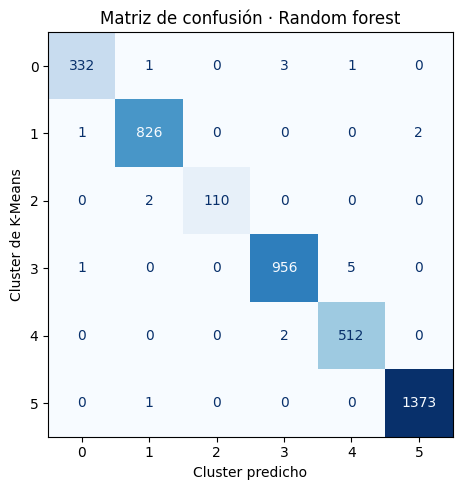

In [14]:
classifier = candidates[best_name].fit(X_train[FEATURES], y_train)
y_pred = classifier.predict(X_test[FEATURES])

print(f"{best_name} · accuracy en test: {accuracy_score(y_test, y_pred):.4f} "
      f"({(y_pred == y_test).sum()} de {len(y_test)})\n")
print(classification_report(y_test, y_pred, digits=4))

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, ax=ax, cmap="Blues", colorbar=False)
ax.set(title=f"Matriz de confusión · {best_name}", xlabel="Cluster predicho", ylabel="Cluster de K-Means")
plt.tight_layout()
plt.show()

In [15]:
errors = X_test.assign(cluster_kmeans=y_test.values, cluster_predicho=y_pred)
errors = errors[errors["cluster_kmeans"] != errors["cluster_predicho"]]
distances = kmeans.transform(errors[FEATURES])
sorted_distances = np.sort(distances, axis=1)
errors = errors.assign(margen=(sorted_distances[:, 1] - sorted_distances[:, 0]).round(3))

print(f"Casas mal clasificadas: {len(errors)}")
print("Margen = diferencia de distancia entre el centro más cercano y el segundo (0 = justo en la frontera)")
errors.sort_values("margen").head(10)

Casas mal clasificadas: 19
Margen = diferencia de distancia entre el centro más cercano y el segundo (0 = justo en la frontera)


,Latitude,Longitude,MedInc,cluster_kmeans,cluster_predicho,margen
8941,34.01,-118.46,4.0000,1,5,0.001
16238,37.98,-121.30,4.1750,3,4,0.002
20099,37.96,-120.24,1.6250,0,3,0.005
16814,37.64,-122.43,4.1033,4,3,0.005
19002,38.34,-121.95,4.2324,3,4,0.005
16560,37.77,-121.37,4.1298,3,4,0.006
9014,34.08,-118.68,3.9934,1,5,0.011
1092,39.82,-121.87,4.5032,3,4,0.011
3035,35.41,-119.19,4.4125,0,1,0.012
9543,37.38,-120.73,1.9236,0,3,0.012


**Interpretación:**

- **Los cuatro modelos superan el 98,9 %.** Es lógico: aprender las etiquetas de K-Means es un problema casi determinista,
  porque cada casa pertenece al centro más cercano.
- **Gana el random forest:** 99,35 % en validación cruzada y **99,54 % en test** (4.109 de 4.128). Todas las clases están
  por encima del 98 % en precisión y recall, incluido el cluster 2, que es el más pequeño.
- **Los 19 errores están en las fronteras entre clusters.** Su margen es casi 0: son casas casi a la misma distancia de
  dos centros, sobre todo con ingresos en torno al umbral de 41.000 $ (`MedInc` ≈ 4). Ni siquiera K-Means las separa con claridad.
- **Hay que valorar el tamaño del modelo:** el random forest ocupa **11,9 MB**, mientras que la regresión logística
  pesaría unos pocos KB y solo pierde 0,3 puntos (99,03 %). Para una aplicación ligera, la logística sería una alternativa válida.

## 5. Guardar los modelos

Guardamos los dos modelos en `models/` con `joblib`, y los conjuntos con su columna `cluster` en `data/processed/`.

In [16]:
MODELS_DIR.mkdir(exist_ok=True)
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

KMEANS_PATH = MODELS_DIR / "kmeans_6_clusters.joblib"
CLASSIFIER_PATH = MODELS_DIR / "cluster_classifier.joblib"
joblib.dump(kmeans, KMEANS_PATH)
joblib.dump(classifier, CLASSIFIER_PATH)

train.to_csv(PROCESSED_DIR / "housing_train_clusters.csv", index=False)
test.to_csv(PROCESSED_DIR / "housing_test_clusters.csv", index=False)

for path in (KMEANS_PATH, CLASSIFIER_PATH):
    print(f"{path.relative_to(PROJECT_ROOT)}: {path.stat().st_size / 1024:.0f} KB")

# Comprobación: los modelos recargados dan las mismas predicciones
same_kmeans = (joblib.load(KMEANS_PATH).predict(X_test) == kmeans.predict(X_test)).all()
same_clf = (joblib.load(CLASSIFIER_PATH).predict(X_test[FEATURES]) == y_pred).all()
print("Predicciones idénticas tras recargar · K-Means:", same_kmeans, "· clasificador:", same_clf)

models/kmeans_6_clusters.joblib: 66 KB
models/cluster_classifier.joblib: 11866 KB


Predicciones idénticas tras recargar · K-Means: True · clasificador: True


## 6. Conclusiones

**1. Las casas de California se agrupan de forma natural en 6 segmentos** que combinan zona (norte, sur o Valle Central)
y nivel de ingreso (bajo-medio, medio-alto o muy alto). El umbral de ingreso que más separa es de unos **41.000 $**, y por
encima de **80.000 $** el ingreso pesa más que la ubicación.

**2. El K-Means generaliza bien:** las casas de test se asignan con la misma calidad que las de entrenamiento
(distancia media al centro de 0,602 frente a 0,609, y un reparto por cluster prácticamente igual).

**3. El modelo supervisado reproduce los clusters casi a la perfección:** el random forest acierta el **99,54 %** de las
casas de test, y sus pocos errores están justo en las fronteras, donde la asignación es ambigua por naturaleza.

**4. El flujo completo funciona:** K-Means etiquetó datos que no tenían etiqueta y el clasificador aprendió esas etiquetas.
Ambos modelos están guardados en `models/`, y `src/app.py` los usa para asignar un segmento a casas nuevas.

**Posibles mejoras:**

- Añadir variables como `HouseAge` o `MedHouseVal` para segmentos más ricos (por ejemplo, zonas caras con ingreso medio).
- Si el modelo se va a desplegar, valorar la regresión logística: es mucho más ligera y apenas pierde precisión.